## 0. The Dataset

This project uses **PAWS-Wiki (Paraphrase Adversaries from Word Scrambling)**, a dataset designed for binary paraphrase detection and introduced by Zhang et al. (2019). Each instance consists of two sentences labelled according to whether they convey the same meaning.

PAWS-Wiki contains sentence pairs with high lexical overlap but potentially different meanings. This makes it particularly challenging for models that rely primarily on word occurrence and frequency.

The dataset was selected to investigate the limitations of lexical representations and assess whether incorporating word-order information improves paraphrase detection.

## 1. Tokenizer and word embedding for PAWS

For this section we should choose a Tokenizer and type of embedding. 

As how to construct an embedding from a word is a non-trivial task in nlp, we will use pre-trained embeddings. This pre-trained embeddings like GloVe, fastText and Word2vec has vocabularies and tokens that are in general quite generic so they can be used for different classification tasks. Therefore, the tokenizer must be compatible with this approach as they must be compatibles, i.e. we should be able to match the general embeddings with the tokens in our corpus. 

Because of this reason, we will discard using sub-words tokenizers (BPE, WordPiece, SentencePiece...), characters tokenizers or hybrid aproaches. We would also avoid to just tokenize our texts by the spaces between words, as this is a too simple approach. We want to preserve the meaning of our sentences pairs to be able to distinguish them, and we would loose information about punctuation that changes the meaning of them doing this. 

Therefore, the tokenizer we will use is the nltk.word_tokenizer() keeping the punctuation and stopwords. To generalize a bit, we will only change the capital letters to lower cases, as it will be extremely unlikely that they change the meaning of a sentence. With PAWS, aggresive changes on the sentences like removing the stopwords would lead to loosing part of the signal; undersating signal as the meaning. E.g. "from Paris to Madrid" and "from Madrid to Paris", removing the stopwords would give the same tokens, "Paris" and "Madrid", and will transform the phrases into indistinguishable by meaning. 



In [6]:
# Load packages
import sys
import matplotlib.pyplot as plt
from pathlib import Path
sys.path.append(str(Path("..").resolve()))
from src.part2_utils import BasicTokenizer, CleanTokenizer, PretrainedEmbeddings, build_embedding_matrix, build_vocab
from src.dataset import load_paws
import pandas as pd
import numpy as np
import torch

In [7]:
# Load and split the PAWS dataset
dataset = load_paws()
train_ds = dataset["train"]
validation_ds = dataset["validation"]
test_ds = dataset["test"]
split_info = pd.DataFrame([
    {
        "Split": split_name,
        "Instances": len(split_data),
        "Columns": ", ".join(split_data.column_names)
    }
    for split_name, split_data in dataset.items()
])

display(split_info)

Removed 63 examples from 31 conflicting pairs.
Training examples remaining: 49,338


,Split,Instances,Columns
0,train,49338,"id, sentence1, sentence2, label"
1,test,8000,"id, sentence1, sentence2, label"
2,validation,8000,"id, sentence1, sentence2, label"


Now, we will create the vocabulary only with the training corpus, to avoid data leakeage, and we would use the NLTK tokenizer as mentioned: 

In [8]:
tokenizer = BasicTokenizer(lowercase = True, remove_punct = False, remove_stopwords = False)

vocab, counts = build_vocab(list(train_ds["sentence1"]) + list(train_ds["sentence2"]), tokenizer = tokenizer)
tokenizer.vocab = vocab


With this choice made, a suitable pre-trained embedding for this would be the GloVe 6B pre-trained embedding (400k words) and the FastText pre-trainned embedding (1M words), both with vectors of size 300 for every word. 

There is also a big difference between these two apart from the vocabulary size, that we will not exploit in our analysis. That is that GloVe does not generate new vectors for unseen words but FastText has the tools to approximate this unseen vectors using the n-gram tokens that has available and calculates a new embedding. The way of approaching these words without a pretrained vector (OOVs) at GloVe and FastText is to set these vector at random according to a seed.  
 

In [ ]:
# We load both pretrained embeddings and apply them to fit the vocabulary
glove = PretrainedEmbeddings(
    "./embed_pretrain_data/glove-300d.txt.gz",
    num_dims=300,
    skip_first_line=True,
)
fasttext = PretrainedEmbeddings(
    "./embed_pretrain_data/fasttext-300d.txt.gz",
    num_dims=300,
    skip_first_line=True,
)

# This step also eliminates characters without traslation in the process to reduce OOV tokens
E_glove, st_glove = build_embedding_matrix(vocab, glove, counts)
E_ft, st_ft = build_embedding_matrix(vocab, fasttext, counts)

torch.save(E_glove, "results/E_glove.pt")
torch.save(E_ft, "results/E_ft.pt")

Using this results we can perform an analysis of how good the embeddings adapt to the vocabulary using the "OOV" tokens as the tokens that does not much any word in the embedding; and "OOV types" as the numbers of pairs of phrases that contains this "OOV tokens":

,Vocab size,OOV types,OOV tokens,freq = 1,freq 2-5,freq 6-50,freq > 50
GloVe 6B,31477,13.66%,1.81%,54.55%,20.51%,12.36%,0.08%
fastText,31477,9.55%,2.36%,47.27%,14.90%,8.18%,0.08%


GloVe 6B most frequent OOV: ['berasia', '×', '→', 'mouhoun', 'aganbegyan', 'eoacmaea', 'eoacmaeidae', 'urechioiu', 'eletrônica', 'shantih']
fastText most frequent OOV: ['``', '_', 'lottiidae', 'aganbegyan', 'eoacmaea', 'eoacmaeidae', 'urechioiu', 'eletrônica', 'leudesius', 'upfa-slfp']


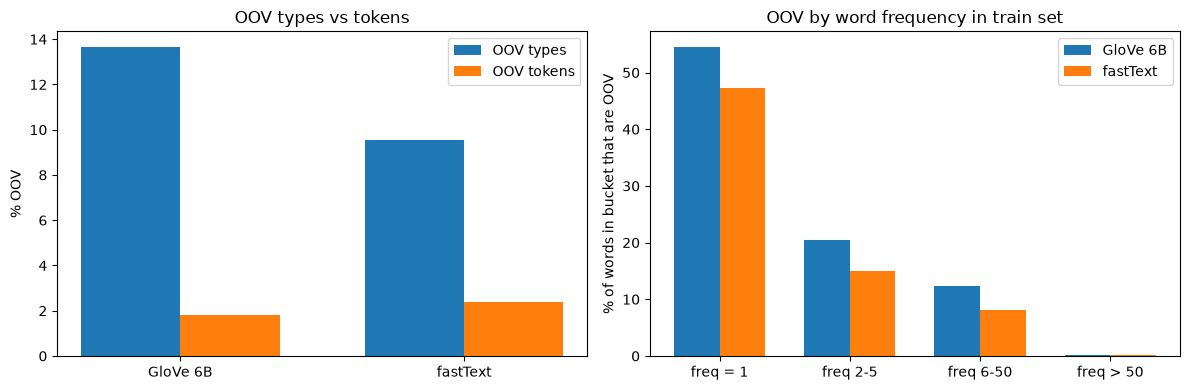

In [10]:
# Anlyse the stats
results = {"GloVe 6B": st_glove, "fastText": st_ft}
df = pd.DataFrame({m: {k: v for k, v in s.items() if k != "top_oov"} for m, s in results.items()}).T
df.insert(0, "Vocab size", len(vocab) - 2)

# Create a table for analysis
display(df.style.format({c: "{:.2%}" for c in df.columns if c != "Vocab size"})
          .set_caption("OOV rate per embedding (lower is better)")
          .highlight_min(axis=0, subset=[c for c in df.columns if c != "Vocab size"], color="#c6efce"))

out_dir = Path("images"); out_dir.mkdir(exist_ok=True)
df.to_csv(out_dir / "oov_table.csv")

# Most frequent OOV words
for m, s in results.items():
    print(f"{m} most frequent OOV: {s['top_oov']}")

# Plot the figures to see stats
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
models = list(results)
x = np.arange(len(models)); w = 0.35

axes[0].bar(x - w/2, [results[m]["OOV types"] * 100 for m in models], w, label="OOV types")
axes[0].bar(x + w/2, [results[m]["OOV tokens"] * 100 for m in models], w, label="OOV tokens")
axes[0].set_xticks(x); axes[0].set_xticklabels(models)
axes[0].set_ylabel("% OOV"); axes[0].set_title("OOV types vs tokens"); axes[0].legend()

BUCKETS = {"freq = 1": (1, 1), "freq 2-5": (2, 5), "freq 6-50": (6, 50), "freq > 50": (51, 10**9)}
bnames = list(BUCKETS)
xb = np.arange(len(bnames))
for i, m in enumerate(models):
    axes[1].bar(xb + (i - 0.5) * w, [results[m][b] * 100 for b in bnames], w, label=m)
axes[1].set_xticks(xb); axes[1].set_xticklabels(bnames)
axes[1].set_ylabel("% of words in bucket that are OOV")
axes[1].set_title("OOV by word frequency in train set"); axes[1].legend()
plt.tight_layout(); plt.show()

fig.savefig(out_dir / "oov_analysis.png", dpi=300, bbox_inches="tight")

According to these results, for both methods, there is around 2% of tokens at the vocabulary without an embedding mapping in our corpus. Being these tokens affecting 13.66% and 9.55% pairs of phrases using GloVe and FastText, respectively, out of all the training corpus. Therefore, from now on we would use the fastText embedding for the analysis of our models, as it covers more than 90% of all the pairs perfectly. 

It is relevant to mention that using the tools of FastCheck to approximate this OOV tokens via N-grams is not really necessary, as the improvement of approximating a unknown embedding to a new one using the exsting ones would be almost not noticiable for such a memory increase for the modeling (~7GB). Even with this percentages of a tenth of all the vocabulary, this OOV tokens most of the times only appears once on the PAWS pairs, not changing much semantically. The mapping of these OOV tokens left by following a Gaussian distribution of the same standard deviation as the rest of the embeddings on the matrix, as implemented, is a good approximation.  